<a href="https://colab.research.google.com/github/Somosree-Projects/Industrial-Machine-Failure-Prediction/blob/main/Industrial_Machine_Failure_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import files
import pandas as pd

uploaded = files.upload()

file_name = next(iter(uploaded))

df = pd.read_csv(file_name)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Saving ai4i2020 (1).csv to ai4i2020 (1) (1).csv
Dataset loaded successfully!
Dataset shape: (10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [ ]:
print("Column names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nDataset information:")
df.info()

print("\nSummary statistics:")
df.describe()

Column names:
['UDI', 'Product ID', 'Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']

Data types:
UDI                          int64
Product ID                  object
Type                        object
Air temperature [K]        float64
Process temperature [K]    float64
Rotational speed [rpm]       int64
Torque [Nm]                float64
Tool wear [min]              int64
Machine failure              int64
TWF                          int64
HDF                          int64
PWF                          int64
OSF                          int64
RNF                          int64
dtype: object

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 n

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


In [ ]:
# Check missing values
print("Missing values:")
print(df.isnull().sum())

# Check duplicate records
print("\nNumber of duplicate records:", df.duplicated().sum())

Missing values:
UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

Number of duplicate records: 0


Machine failure distribution:
Machine failure
0    9661
1     339
Name: count, dtype: int64


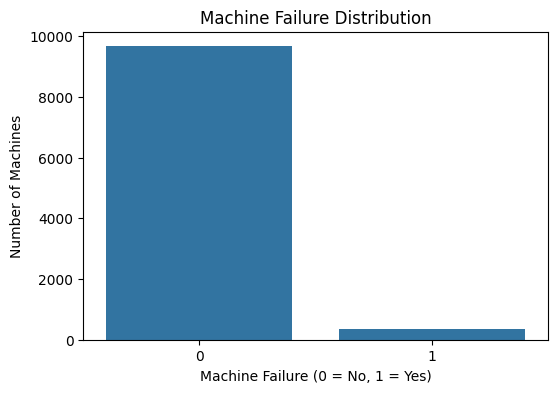

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Count failed and non-failed machines
failure_counts = df["Machine failure"].value_counts().sort_index()

print("Machine failure distribution:")
print(failure_counts)

# Plot the distribution
plt.figure(figsize=(6, 4))

sns.countplot(
    data=df,
    x="Machine failure"
)

plt.title("Machine Failure Distribution")
plt.xlabel("Machine Failure (0 = No, 1 = Yes)")
plt.ylabel("Number of Machines")

plt.show()

       Air temperature [K]  Process temperature [K]  Rotational speed [rpm]  \
count         10000.000000             10000.000000            10000.000000   
mean            300.004930               310.005560             1538.776100   
std               2.000259                 1.483734              179.284096   
min             295.300000               305.700000             1168.000000   
25%             298.300000               308.800000             1423.000000   
50%             300.100000               310.100000             1503.000000   
75%             301.500000               311.100000             1612.000000   
max             304.500000               313.800000             2886.000000   

        Torque [Nm]  Tool wear [min]  
count  10000.000000     10000.000000  
mean      39.986910       107.951000  
std        9.968934        63.654147  
min        3.800000         0.000000  
25%       33.200000        53.000000  
50%       40.100000       108.000000  
75%       46.80

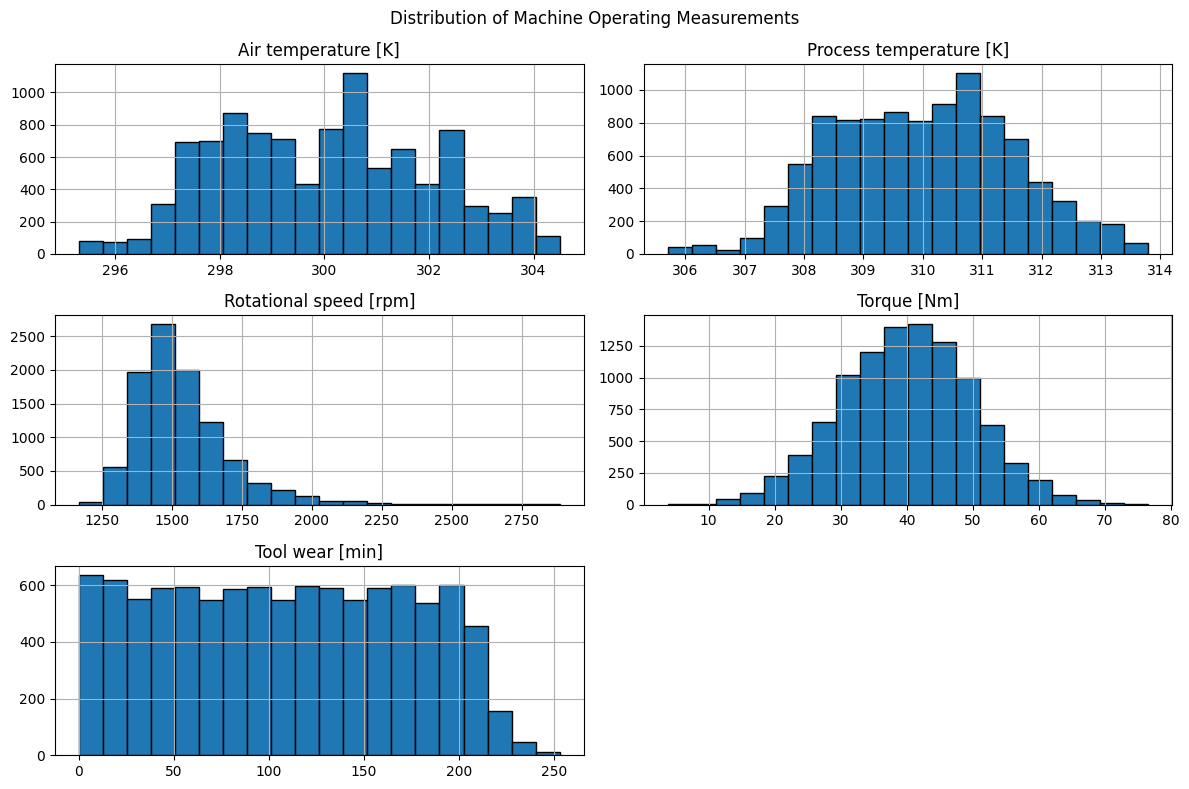

In [ ]:
# Select important numerical features
features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

# Display summary statistics
print(df[features].describe())

# Plot feature distributions
df[features].hist(
    figsize=(12, 8),
    bins=20,
    edgecolor="black"
)

plt.suptitle("Distribution of Machine Operating Measurements")
plt.tight_layout()
plt.show()

                 Air temperature [K]  Process temperature [K]  \
Machine failure                                                 
0                             299.97                   310.00   
1                             300.89                   310.29   

                 Rotational speed [rpm]  Torque [Nm]  Tool wear [min]  
Machine failure                                                        
0                               1540.26        39.63           106.69  
1                               1496.49        50.17           143.78  


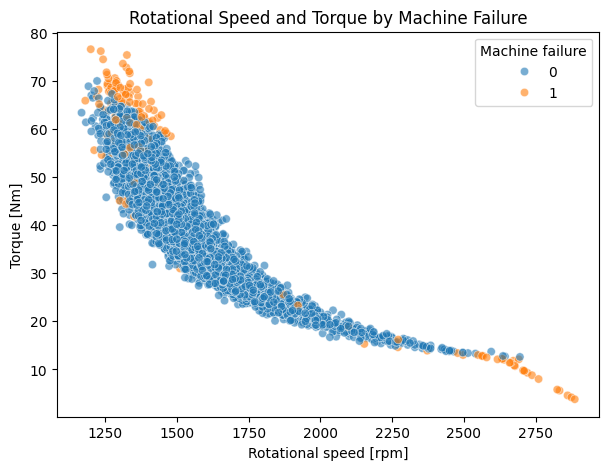

In [ ]:
# Compare average measurements for failed and non-failed machines
print(
    df.groupby("Machine failure")[features]
    .mean()
    .round(2)
)

# Plot the relationship between torque and rotational speed
plt.figure(figsize=(7, 5))

sns.scatterplot(
    data=df,
    x="Rotational speed [rpm]",
    y="Torque [Nm]",
    hue="Machine failure",
    alpha=0.6
)

plt.title("Rotational Speed and Torque by Machine Failure")
plt.show()

In [ ]:
# Remove unnecessary and failure-related columns
df_clean = df.drop(
    columns=[
        "UDI",
        "Product ID",
        "TWF",
        "HDF",
        "PWF",
        "OSF",
        "RNF"
    ]
)

# Separate input features and target
X = df_clean.drop("Machine failure", axis=1)
y = df_clean["Machine failure"]

print("Input features:")
print(X.columns.tolist())

print("\nTarget variable:")
print(y.name)

print("\nFeature dataset shape:", X.shape)
print("Target dataset shape:", y.shape)

Input features:
['Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']

Target variable:
Machine failure

Feature dataset shape: (10000, 6)
Target dataset shape: (10000,)


In [ ]:
# Convert categorical features into numerical features
X = pd.get_dummies(
    X,
    columns=["Type"],
    dtype=int
)

print("Encoded dataset:")
print(X.head())

print("\nFinal feature columns:")
print(X.columns.tolist())

print("\nFinal dataset shape:", X.shape)

Encoded dataset:
   Air temperature [K]  Process temperature [K]  Rotational speed [rpm]  \
0                298.1                    308.6                    1551   
1                298.2                    308.7                    1408   
2                298.1                    308.5                    1498   
3                298.2                    308.6                    1433   
4                298.2                    308.7                    1408   

   Torque [Nm]  Tool wear [min]  Type_H  Type_L  Type_M  
0         42.8                0       0       0       1  
1         46.3                3       0       1       0  
2         49.4                5       0       1       0  
3         39.5                7       0       1       0  
4         40.0                9       0       1       0  

Final feature columns:
['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Type_H', 'Type_L', 'Type_M']

Final dataset shap

In [ ]:
# Check missing values
print("Missing values:")
print(X.isnull().sum().sum())

# Check target distribution
print("\nTarget distribution:")
print(y.value_counts())

# Check final dataset information
print("\nFinal feature information:")
X.info()

Missing values:
0

Target distribution:
Machine failure
0    9661
1     339
Name: count, dtype: int64

Final feature information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Air temperature [K]      10000 non-null  float64
 1   Process temperature [K]  10000 non-null  float64
 2   Rotational speed [rpm]   10000 non-null  int64  
 3   Torque [Nm]              10000 non-null  float64
 4   Tool wear [min]          10000 non-null  int64  
 5   Type_H                   10000 non-null  int64  
 6   Type_L                   10000 non-null  int64  
 7   Type_M                   10000 non-null  int64  
dtypes: float64(3), int64(5)
memory usage: 625.1 KB


In [ ]:
from sklearn.model_selection import train_test_split

# Split the dataset into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display the dataset sizes
print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("\nTraining target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

Training data shape: (8000, 8)
Testing data shape: (2000, 8)

Training target shape: (8000,)
Testing target shape: (2000,)


In [ ]:
# Check the distribution of machine failures
print("Training data distribution:")
print(y_train.value_counts())

print("\nTesting data distribution:")
print(y_test.value_counts())

Training data distribution:
Machine failure
0    7729
1     271
Name: count, dtype: int64

Testing data distribution:
Machine failure
0    1932
1      68
Name: count, dtype: int64


**Step 6: Train the three classification models**

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

In [ ]:
# Logistic Regression
logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# Decision Tree
decision_tree_model = DecisionTreeClassifier(
    random_state=42
)

# Random Forest
random_forest_model = RandomForestClassifier(
    random_state=42
)

# Store all models in a dictionary
models = {
    "Logistic Regression": logistic_model,
    "Decision Tree": decision_tree_model,
    "Random Forest": random_forest_model
}

In [ ]:
# Train each model using the training data
for name, model in models.items():
    model.fit(X_train, y_train)
    print(name, "trained successfully!")

Logistic Regression trained successfully!
Decision Tree trained successfully!
Random Forest trained successfully!


In [ ]:
# Predict machine failures using each trained model
predictions = {}

for name, model in models.items():
    predictions[name] = model.predict(X_test)

print("Predictions completed successfully!")

Predictions completed successfully!


**Step 7: Evaluate and compare the models**

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Store evaluation results
results = []

for name, model in models.items():

    # Predict using the testing data
    y_pred = model.predict(X_test)

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test, y_pred, zero_division=0
    )

    recall = recall_score(
        y_test, y_pred, zero_division=0
    )

    f1 = f1_score(
        y_test, y_pred, zero_division=0
    )

    # Store the results
    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1
    })

# Display the comparison table
results_df = pd.DataFrame(results)

print("Model Performance Comparison:")
print(results_df.round(4))

Model Performance Comparison:
                 Model  Accuracy  Precision  Recall  F1-Score
0  Logistic Regression    0.9675     0.6364  0.1029    0.1772
1        Decision Tree    0.9785     0.6866  0.6765    0.6815
2        Random Forest    0.9810     0.8947  0.5000    0.6415



 Logistic Regression
[[1928    4]
 [  61    7]]


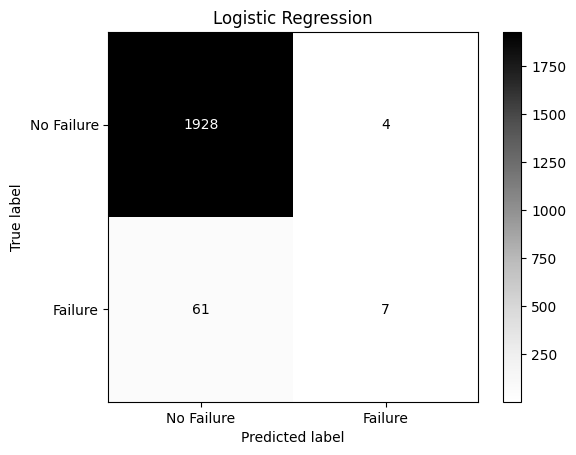


 Decision Tree
[[1911   21]
 [  22   46]]


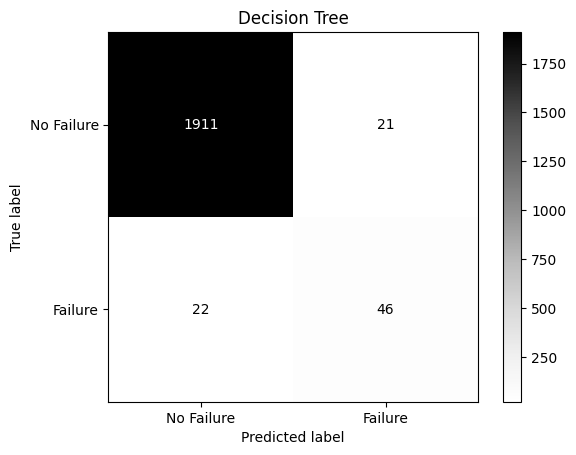


 Random Forest
[[1928    4]
 [  34   34]]


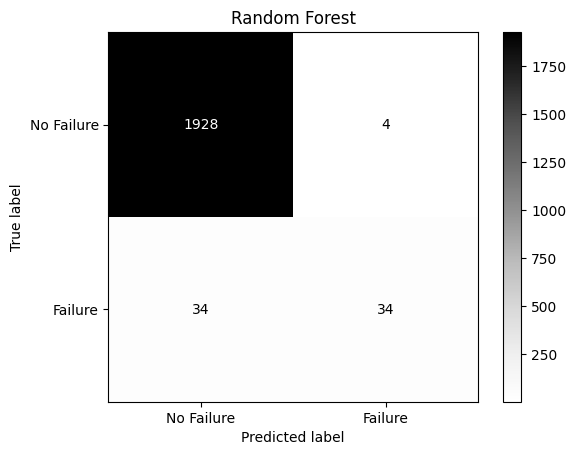

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

for name, model in models.items():

    y_pred = model.predict(X_test)

    cm = confusion_matrix(y_test, y_pred)

    print("\n", name)

    print(cm)

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["No Failure", "Failure"]
    ).plot(cmap="Greys")

    plt.title(name)
    plt.show()

**Step 8: Perform 5-fold cross-validation**

In [ ]:
from sklearn.model_selection import cross_val_score

# Store cross-validation results
cv_results = []

for name, model in models.items():

    # Perform 5-fold cross-validation
    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=5,
        scoring="f1"
    )

    # Store the results
    cv_results.append({
        "Model": name,
        "Fold 1": scores[0],
        "Fold 2": scores[1],
        "Fold 3": scores[2],
        "Fold 4": scores[3],
        "Fold 5": scores[4],
        "Average F1-Score": scores.mean()
    })

# Display the cross-validation results
cv_df = pd.DataFrame(cv_results)

print("5-Fold Cross-Validation Results:")
print(cv_df.round(4))

5-Fold Cross-Validation Results:
                 Model  Fold 1  Fold 2  Fold 3  Fold 4  Fold 5  \
0  Logistic Regression  0.4054  0.1935  0.3611  0.3077  0.2121   
1        Decision Tree  0.6481  0.6607  0.6909  0.6780  0.6429   
2        Random Forest  0.6207  0.6585  0.7174  0.6897  0.5926   

   Average F1-Score  
0            0.2960  
1            0.6641  
2            0.6558  


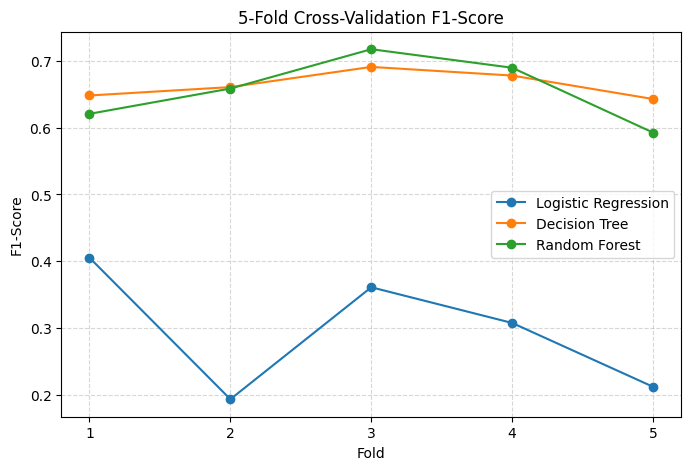

In [ ]:
plt.figure(figsize=(8, 5))

for name, model in models.items():

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=5,
        scoring="f1"
    )

    plt.plot(
        range(1, 6),
        scores,
        marker="o",
        label=name
    )

plt.title("5-Fold Cross-Validation F1-Score")
plt.xlabel("Fold")
plt.ylabel("F1-Score")
plt.xticks(range(1, 6))
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

**Step 9: Hyperparameter tuning using GridSearchCV**

In [ ]:
from sklearn.model_selection import GridSearchCV

# Define the hyperparameter settings for each model
param_grids = {
    "Logistic Regression": {
        "model__C": [0.1, 1, 10]
    },

    "Decision Tree": {
        "max_depth": [5, 10, None],
        "min_samples_leaf": [1, 5]
    },

    "Random Forest": {
        "n_estimators": [100, 200],
        "max_depth": [10, None],
        "min_samples_leaf": [1, 5]
    }
}

In [ ]:
# Store the tuned models and their results
tuned_models = {}
tuning_results = []

for name, model in models.items():

    # Create GridSearchCV
    grid_search = GridSearchCV(
        estimator=model,
        param_grid=param_grids[name],
        scoring="f1",
        cv=5,
        n_jobs=-1
    )

    # Train and tune using training data
    grid_search.fit(X_train, y_train)

    # Save the best model
    tuned_models[name] = grid_search.best_estimator_

    # Store the results
    tuning_results.append({
        "Model": name,
        "Best Parameters": grid_search.best_params_,
        "Best CV F1-Score": grid_search.best_score_
    })

    print(name, "tuning completed!")

Logistic Regression tuning completed!
Decision Tree tuning completed!
Random Forest tuning completed!


In [ ]:
tuning_df = pd.DataFrame(tuning_results)

print("Hyperparameter Tuning Results:")
print(tuning_df.to_string(index=False))

Hyperparameter Tuning Results:
              Model                                                 Best Parameters  Best CV F1-Score
Logistic Regression                                                {'model__C': 10}          0.326099
      Decision Tree                        {'max_depth': 10, 'min_samples_leaf': 1}          0.720586
      Random Forest {'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 100}          0.655773


**Step 10: Select the best model and perform final evaluation**

Best Model: Decision Tree

Final Classification Report:
              precision    recall  f1-score   support

  No Failure       0.99      0.99      0.99      1932
     Failure       0.82      0.68      0.74        68

    accuracy                           0.98      2000
   macro avg       0.91      0.84      0.87      2000
weighted avg       0.98      0.98      0.98      2000



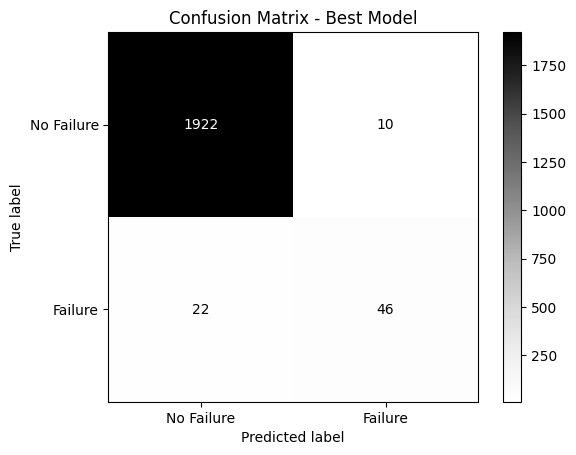

In [ ]:
from sklearn.metrics import classification_report

# Select the model with the highest CV F1-score
best_model_name = max(
    tuning_results,
    key=lambda result: result["Best CV F1-Score"]
)["Model"]

best_model = tuned_models[best_model_name]

print("Best Model:", best_model_name)

# Predict using the test data
y_pred = best_model.predict(X_test)

# Display final evaluation
print("\nFinal Classification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["No Failure", "Failure"],
    zero_division=0
))

# Display the confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["No Failure", "Failure"],
    cmap="Greys"
)

plt.title("Confusion Matrix - Best Model")
plt.show()

**Step 11: Save the best model and preprocessing pipeline**

In [ ]:
import joblib

model_data = {
    "model": best_model,
    "feature_names": list(X.columns)
}

joblib.dump(model_data, "machine_failure_model.pkl")

print("Best model and feature names saved successfully!")

Best model and feature names saved successfully!


In [ ]:
from google.colab import files

files.download("machine_failure_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Step 12: Build a new machine failure prediction system**

In [ ]:
import joblib

model_data = joblib.load("machine_failure_model.pkl")

loaded_model = model_data["model"]
feature_names = model_data["feature_names"]

print("Saved model loaded successfully!")

Saved model loaded successfully!


In [ ]:
def predict_machine_failure():

    print("ENTER MACHINE DETAILS")

    machine_type = input("Machine Type (L/M/H): ").upper()

    if machine_type not in ["L", "M", "H"]:
        print("Invalid machine type!")
        return

    air_temp = float(input("Air Temperature [K]: "))
    process_temp = float(input("Process Temperature [K]: "))
    speed = float(input("Rotational Speed [rpm]: "))
    torque = float(input("Torque [Nm]: "))
    tool_wear = float(input("Tool Wear [min]: "))

    # Prepare the input data
    new_data = {
        "Air temperature [K]": air_temp,
        "Process temperature [K]": process_temp,
        "Rotational speed [rpm]": speed,
        "Torque [Nm]": torque,
        "Tool wear [min]": tool_wear,
        "Type_H": 1 if machine_type == "H" else 0,
        "Type_L": 1 if machine_type == "L" else 0,
        "Type_M": 1 if machine_type == "M" else 0
    }

    # Arrange features in the training column order
    input_df = pd.DataFrame([new_data], columns=feature_names)

    # Predict machine failure
    prediction = loaded_model.predict(input_df)[0]

    print("\n========== PREDICTION RESULT ==========")

    if prediction == 1:
        print("Machine Failure: YES")
    else:
        print("Machine Failure: NO")

    # Display estimated failure probability
    if hasattr(loaded_model, "predict_proba"):

        probability = loaded_model.predict_proba(input_df)[0][1]

        print(
            "Estimated Failure Probability:",
            round(probability * 100, 2), "%"
        )

    print("======================================")

In [ ]:
predict_machine_failure()

ENTER MACHINE DETAILS
Machine Type (L/M/H): H
Air Temperature [K]: 295
Process Temperature [K]: 305
Rotational Speed [rpm]: 1800
Torque [Nm]: 25
Tool Wear [min]: 30

========== PREDICTION RESULT ==========
Machine Failure: NO
Estimated Failure Probability: 0.04 %
